# Exam Project 2: Customer Churn Prediction — E-Commerce Platform

**Course:** AI for Communication and Marketing — B.Sc. in Artificial Intelligence  
**Dataset:** E-Commerce customer profiles, satisfaction scores, and transaction summaries  
**Goal:** Build a Propensity Model to identify customers at risk of churning using Logistic Regression, Random Forest and XGBoost

## Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, auc,
                             precision_recall_curve, average_precision_score)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
SEED = 42

print('Libraries loaded ✓')

Libraries loaded ✓


---
## Task A — Data Audit & Quality

In this section, the dataset is loaded, then perform an audit and handle missing values, inconsistencies, and outliers.

### A.0 — Loading the Dataset

In [2]:
# Load the dataset
file_path = 'data.xlsx'
df = pd.read_excel(file_path)

# Display initial information
print("Dataset Shape:", df.shape)
df.info()
df.describe()

Dataset Shape: (5630, 20)
<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5628 non-null   float64
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5628 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  Num

,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
count,5628.000000,5630.000000,5366.000000,5630.000000,5379.000000,5375.000000,5630.000000,5630.000000,5630.000000,5630.000000,5365.000000,5374.000000,5372.000000,5323.000000,5630.000000
mean,52814.549041,0.168384,10.189899,1.654707,15.639896,2.931535,3.688988,3.066785,4.214032,0.284902,15.707922,1.751023,3.008004,4.543491,532.401057
std,1624.890759,0.374240,8.557241,0.915389,8.531475,0.721926,1.023999,1.380194,2.583586,0.451408,3.675485,1.894621,2.939680,3.654433,18842.837049
min,50001.000000,0.000000,0.000000,1.000000,5.000000,0.000000,1.000000,1.000000,1.000000,0.000000,11.000000,0.000000,1.000000,0.000000,0.000000
25%,51407.750000,0.000000,2.000000,1.000000,9.000000,2.000000,3.000000,2.000000,2.000000,0.000000,13.000000,1.000000,1.000000,2.000000,145.770000
50%,52814.500000,0.000000,9.000000,1.000000,14.000000,3.000000,4.000000,3.000000,3.000000,0.000000,15.000000,1.000000,2.000000,3.000000,163.330000
75%,54221.250000,0.000000,16.000000,3.000000,20.000000,3.000000,4.000000,4.000000,6.000000,1.000000,18.000000,2.000000,3.000000,7.000000,196.422500
max,55630.000000,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,26.000000,16.000000,16.000000,46.000000,999999.000000


### A.1 — Handling Missing Values

In [3]:
print("\nMissing Values per Column:")
missing = df.isnull().sum()
print(missing[missing > 0])


Missing Values per Column:
CustomerID                       2
Tenure                         264
WarehouseToHome                251
Gender                           2
HourSpendOnApp                 255
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
dtype: int64


In [4]:
# Strategy:
# - 'CustomerID': Drop the 2 rows as it's a unique identifier.
# - 'Gender': Drop the 2 rows.
# - Numerical columns (Tenure, WarehouseToHome, HourSpendOnApp, OrderAmountHikeFromlastYear, CouponUsed, OrderCount, DaySinceLastOrder): I will impute these with the median to be robust against outliers.

# Drop missing CustomerID and Gender
df = df.dropna(subset=['CustomerID', 'Gender'])

# Impute missing numerical values with median
num_cols_with_na = ['Tenure', 'WarehouseToHome', 'HourSpendOnApp', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder']
for col in num_cols_with_na:
    df[col] = df[col].fillna(df[col].median())

print(f"\nRemaining missing values: {df.isnull().sum().sum()}")


Remaining missing values: 0


### A.2 — Data Consistency

In [5]:
# 'PreferredLoginDevice' consistency
print("Original PreferredLoginDevice:", df['PreferredLoginDevice'].unique())
# "Phone" and "Mobile Phone" both refer to a mobile device (a login device cannot be a landline).
# We unify them under "Mobile Phone" for consistency.
df['PreferredLoginDevice'] = df['PreferredLoginDevice'].replace({'Phone': 'Mobile Phone'})
# Drop the few "N.A." rows to avoid biasing the analysis
df = df[df['PreferredLoginDevice'] != 'N.A.']

# 'PreferredPaymentMode' consistency
print("Original PreferredPaymentMode:", df['PreferredPaymentMode'].unique())
df['PreferredPaymentMode'] = df['PreferredPaymentMode'].replace({'CC': 'Credit Card', 'COD': 'Cash on Delivery'})

# 'PreferedOrderCat' consistency
print("Original PreferedOrderCat:", df['PreferedOrderCat'].unique())
df['PreferedOrderCat'] = df['PreferedOrderCat'].replace({'Mobile': 'Mobile Phone'})

Original PreferredLoginDevice: <StringArray>
['Mobile Phone', 'Phone', 'Computer', 'N.A.']
Length: 4, dtype: str
Original PreferredPaymentMode: <StringArray>
['Debit Card', 'UPI', 'CC', 'Cash on Delivery', 'E wallet', 'COD',
 'Credit Card']
Length: 7, dtype: str
Original PreferedOrderCat: <StringArray>
['Laptop & Accessory', 'Mobile', 'Mobile Phone', 'Others', 'Fashion',
 'Grocery']
Length: 6, dtype: str


In [6]:
print("\nAfter cleanup:")
print("PreferredLoginDevice:", df['PreferredLoginDevice'].unique())
print("PreferredPaymentMode:", df['PreferredPaymentMode'].unique())
print("PreferedOrderCat:", df['PreferedOrderCat'].unique())


After cleanup:
PreferredLoginDevice: <StringArray>
['Mobile Phone', 'Computer']
Length: 2, dtype: str
PreferredPaymentMode: <StringArray>
['Debit Card', 'UPI', 'Credit Card', 'Cash on Delivery', 'E wallet']
Length: 5, dtype: str
PreferedOrderCat: <StringArray>
['Laptop & Accessory', 'Mobile Phone', 'Others', 'Fashion', 'Grocery']
Length: 5, dtype: str


### A.3 — Outlier Checking & Treatment

For completeness, I visually inspect all **continuous** or **count** variables (such as `Tenure`, `WarehouseToHome`, `CashbackAmount`, `OrderAmountHikeFromlastYear`, `DaySinceLastOrder`, etc.).

I here deliberately excluded ordinal, categorical or binary variables (such as `SatisfactionScore`, `CityTier`, `Complain`, `NumberOfDeviceRegistered`): these features operate on very narrow, predefined ranges (e.g., scores from 1 to 5, or 0/1 values). For such variables, the statistical concept of "outliers" calculated via interquartile range (used by boxplots) makes no sense.

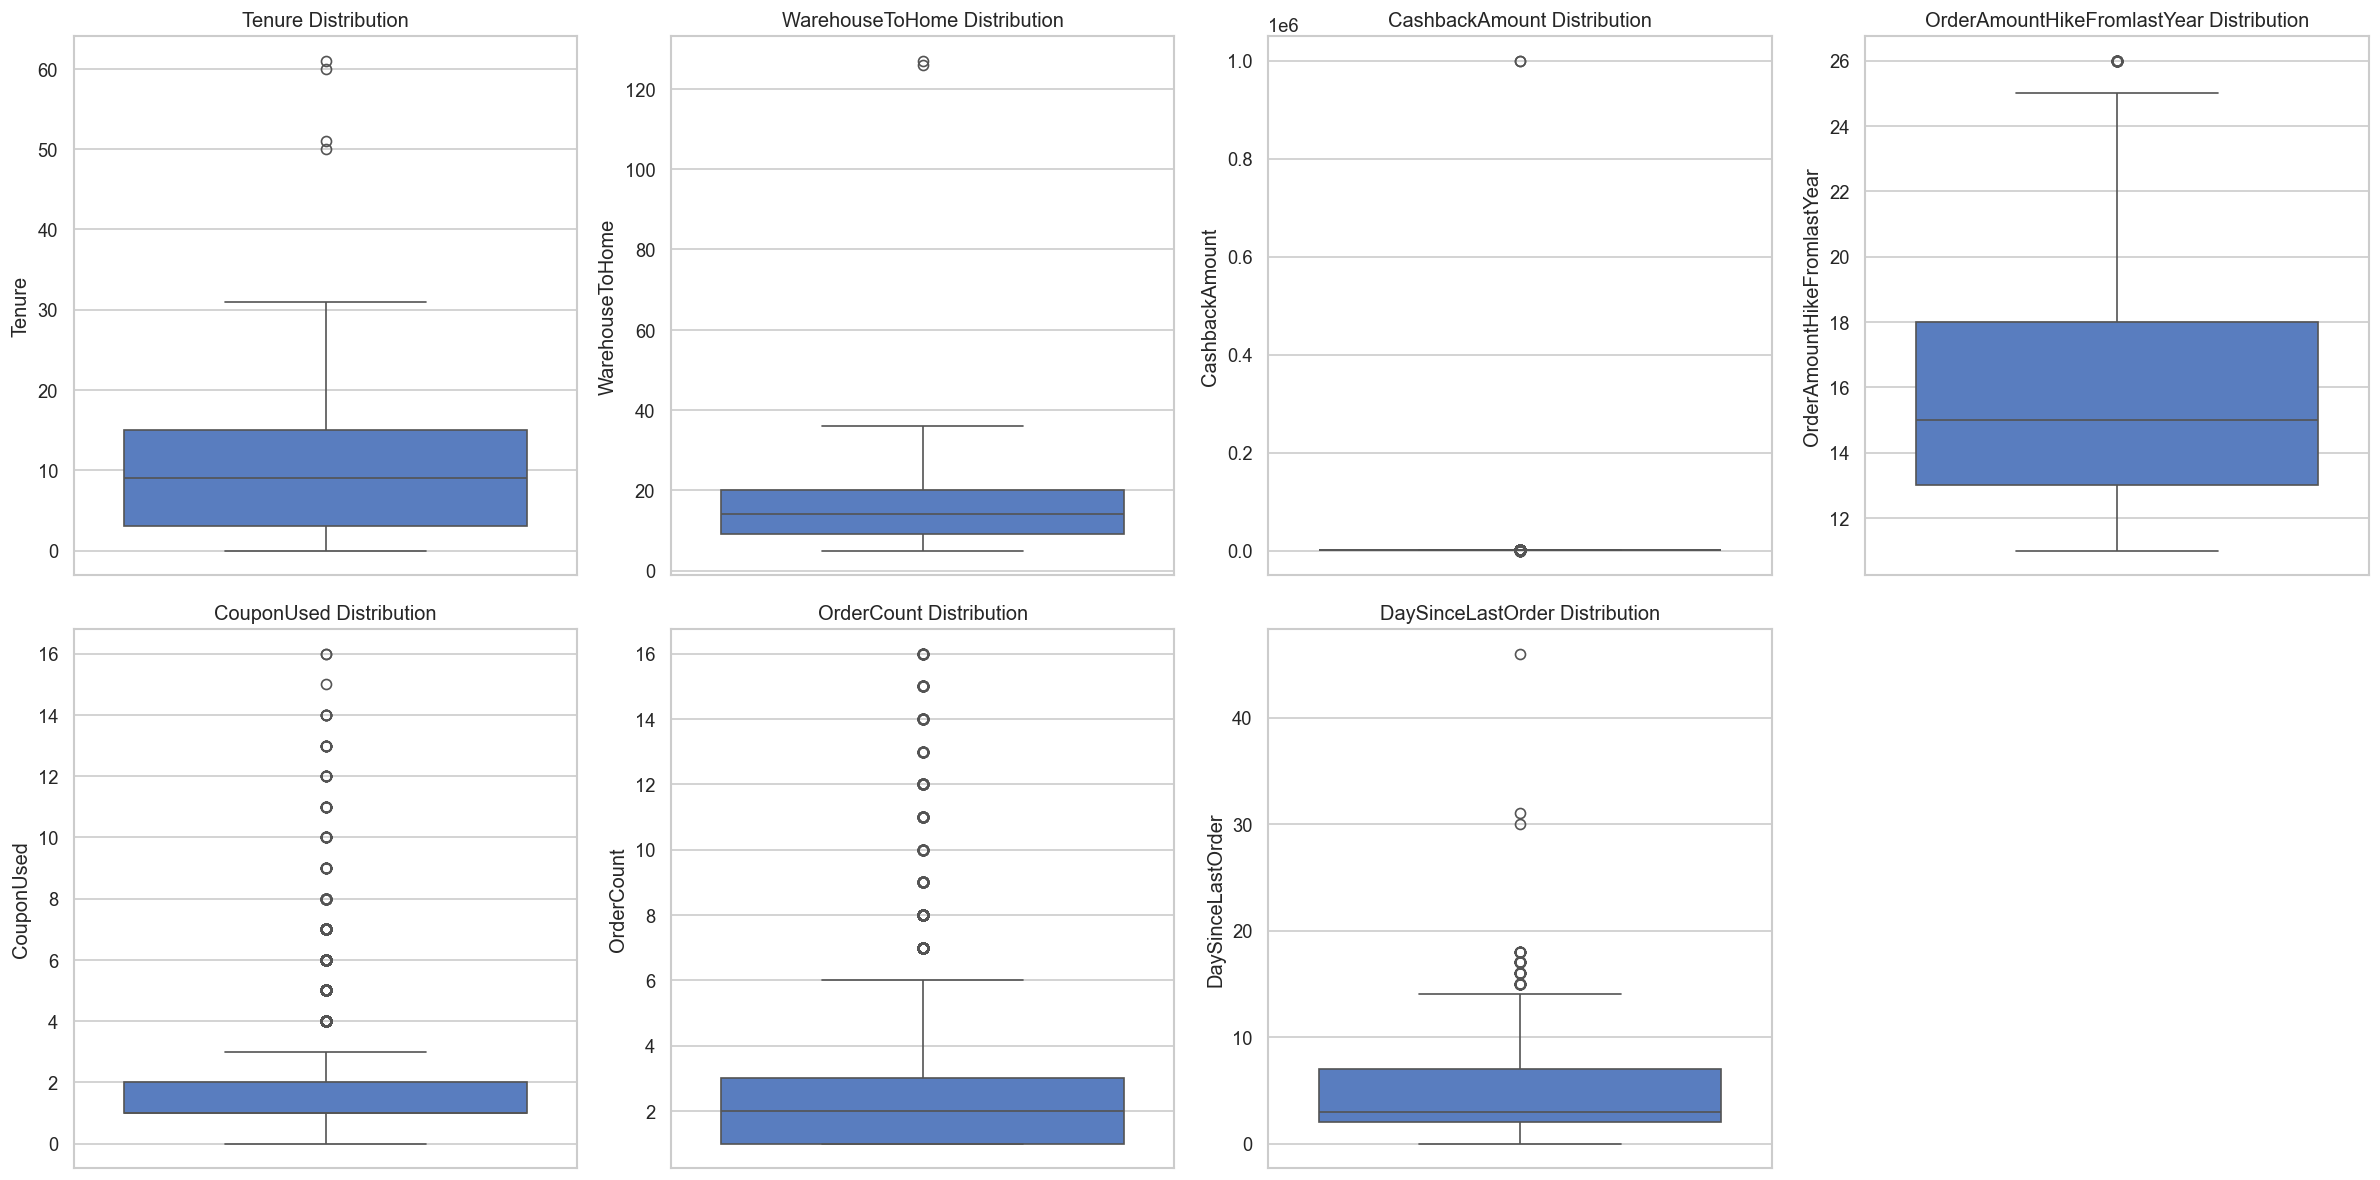

In [7]:
cols_to_check = ['Tenure', 'WarehouseToHome', 'CashbackAmount', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(cols_to_check):
    sns.boxplot(y=df[col], ax=axes[i]).set_title(f'{col} Distribution')

# Hide the empty subplot
axes[7].set_axis_off()
plt.tight_layout()
plt.show()

As can be seen from the graphs, `CashbackAmount` exhibits unrealistic peaks (e.g., a value of 999999) and other variables exhibit long right-tails.

Rather than removing these rows (which would result in a significant loss of valuable data), I apply the **99th percentile capping technique**, which captures values ​​above the 99% threshold and "squashes" them to that cutoff, eliminating extreme noise while preserving the information in the other columns for those customers.

In [8]:
def cap_outliers(series, upper_percentile=0.99):
    upper_limit = series.quantile(upper_percentile)
    return np.where(series > upper_limit, upper_limit, series)

# Apply capping to variables that show significant long tails or extreme outliers
for col in cols_to_check:
    df[col] = cap_outliers(df[col])
    
print("Outliers capped at 99th percentile for continuous/count variables.")

Outliers capped at 99th percentile for continuous/count variables.



Max values after capping:
Tenure                          30.000
WarehouseToHome                 35.000
CashbackAmount                 319.032
OrderAmountHikeFromlastYear     25.000
CouponUsed                       9.000
OrderCount                      14.000
DaySinceLastOrder               15.000
dtype: float64

--- Distributions AFTER Capping ---


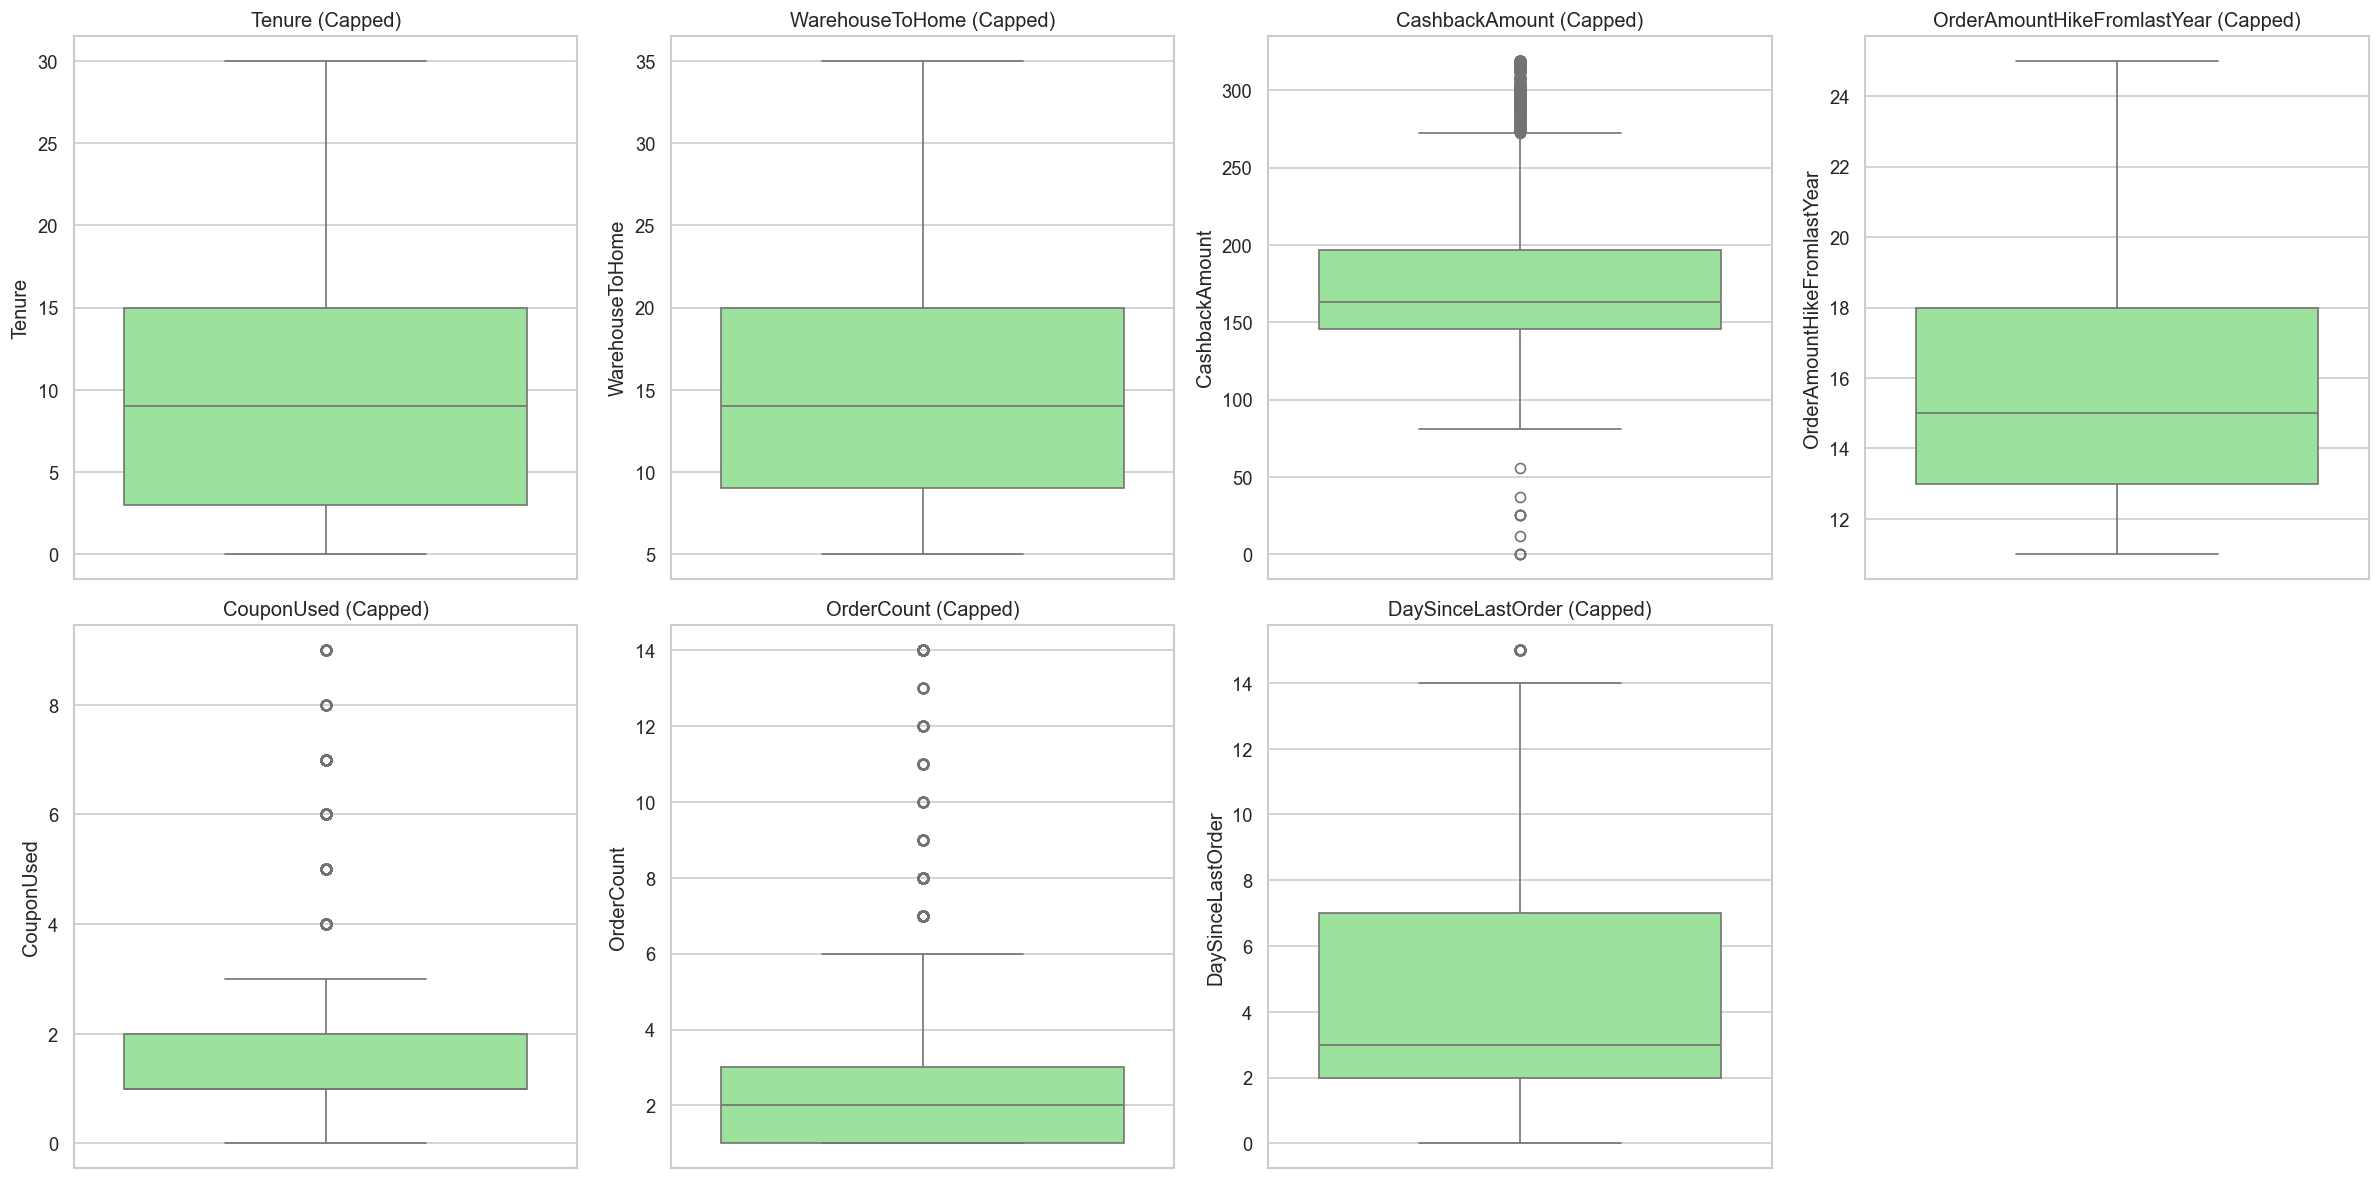

In [9]:
# Verification: check the new max values to ensure capping worked
print("\nMax values after capping:")
print(df[cols_to_check].max())

# Verification: Redraw boxplots to show the effect of capping
print("\n--- Distributions AFTER Capping ---")
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(cols_to_check):
    sns.boxplot(y=df[col], ax=axes[i], color='lightgreen').set_title(f'{col} (Capped)')

axes[7].set_axis_off()
plt.tight_layout()
plt.show()

### A.4 — Encoding Categorical Variables

In [10]:
# For machine learning, we need to convert categorical variables into numerical ones
# I will use here One-Hot Encoding (pd.get_dummies) for categorical columns with low cardinality.

cat_cols = ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

print("Original shape:", df.shape)
print("Encoded shape:", df_encoded.shape)
df_encoded.head()

Original shape: (5621, 20)
Encoded shape: (5621, 28)


,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,...,PreferredPaymentMode_E wallet,PreferredPaymentMode_UPI,Gender_Male,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile Phone,PreferedOrderCat_Others,MaritalStatus_Married,MaritalStatus_Single,MaritalStatus_Widow
0,50001.0,1,4.0,3,6.0,3.0,3,2,9,1,...,False,False,False,False,True,False,False,False,True,False
1,50002.0,1,9.0,1,8.0,3.0,4,3,7,1,...,False,True,True,False,False,True,False,False,True,False
2,50003.0,1,9.0,1,30.0,2.0,4,3,6,1,...,False,False,True,False,False,True,False,False,True,False
3,50004.0,1,0.0,3,15.0,2.0,4,5,8,0,...,False,False,True,False,True,False,False,False,True,False
4,50005.0,1,0.0,1,12.0,3.0,3,5,3,0,...,False,False,True,False,False,True,False,False,True,False


### Documentation of Cleaning Process

1. **Handling Missing Values:** 
   - `CustomerID` and `Gender` had very few missing values (2 each). Since `CustomerID` is essential for unique identification, these rows were dropped.
   - Numerical columns with missing values (e.g., `Tenure`, `WarehouseToHome`) were imputed using the **median**. The median is less sensitive to outliers compared to the mean, providing a more robust imputation.

2. **Data Consistency:** 
   - Addressed inconsistent naming conventions in categorical variables. `CC` was merged into `Credit Card` and `COD` into `Cash on Delivery`. `Mobile` was merged into `Mobile Phone` for order categories.
   - `Phone` and `Mobile Phone` in `PreferredLoginDevice` were unified under `Mobile Phone`, since a login device cannot realistically be a landline — both labels refer to a mobile device.   
   - Rows with `N.A.` in `PreferredLoginDevice` were dropped (only 5 rows) to avoid introducing bias into the market analysis by imputing them with the mode.

3. **Outliers:** 
   - For completeness, we visually checked all continuous and count variables (`Tenure`, `WarehouseToHome`, `CashbackAmount`, `OrderAmountHikeFromlastYear`, `CouponUsed`, `OrderCount`, `DaySinceLastOrder`) using boxplots. Variables like `SatisfactionScore` or `CityTier` were excluded from this specific check because they are ordinal/discrete with strictly predefined short ranges where the concept of continuous outliers does not apply.
   - A visual boxplot inspection revealed extreme outliers in `CashbackAmount` (e.g., values of 999999) and long right tails in variables like `WarehouseToHome` and `DaySinceLastOrder`.
   - Instead of dropping them (which could lead to data loss), we **capped the outliers** at the 99th percentile across these continuous/count features. This preserves the information while reducing the undue influence of extreme values on machine learning models.

4. **Encoding:**
   - Categorical variables were transformed using **One-Hot Encoding** (`drop_first=True` to avoid multicollinearity), making the data fully numeric and compatible with standard machine learning algorithms.

---
## Task B — Exploratory Data Analysis (EDA)

In this section, the class balance is analyzed and then investigate specific correlations and visualize the impact of time-based features on churn probability.

### B.1 — Class Balance Analysis

Understanding the ratio of churners to non-churners is a critical first step. A highly imbalanced dataset (e.g., very few churners) will bias machine learning models towards predicting the majority class. 

**Note on Target Variable (`Churn`):**

Before proceeding with the analysis, it is important to clarify the encoding of our target variable:

- **`1` (Churner):** A customer who has abandoned the service (Positive Class). This is the primary event of interest.
- **`0` (Non-Churner):** A loyal customer who continues to use the service (Negative Class).

Since identifying churners is the core objective of this project, all subsequent models and evaluation metrics will focus on the ability to correctly detect class `1`.

Churn counts:
 Churn
0    4674
1     947
Name: count, dtype: int64

Churn percentages:
 Churn
0    83.152464
1    16.847536
Name: proportion, dtype: float64


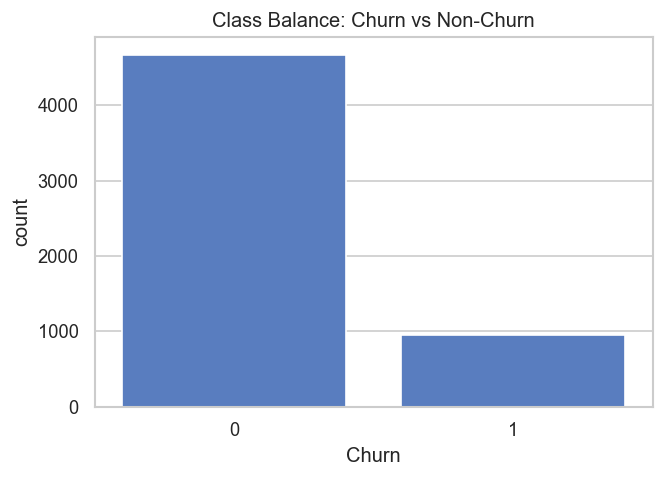

In [11]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Churn', data=df)
plt.title('Class Balance: Churn vs Non-Churn')

churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100
print("Churn counts:\n", churn_counts)
print("\nChurn percentages:\n", churn_pct)

plt.show()

### B.2 — Correlation Analysis

Analyzing the linear correlation between specific variables (`Complain`, `SatisfactionScore`) and our target (`Churn`) provides immediate business insights. It helps validate business hypotheses (e.g., *"Do dissatisfied customers churn more?"*) and identifies which features might be the strongest predictors for the machine learning model.

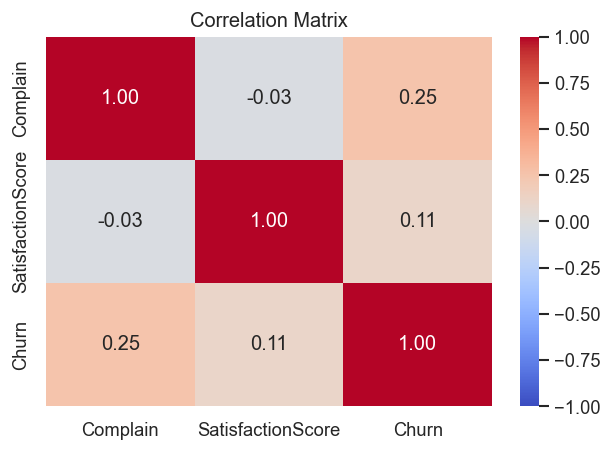

Correlation with Churn:
Complain             0.250328
SatisfactionScore    0.105098
Name: Churn, dtype: float64


In [12]:
corr_cols = ['Complain', 'SatisfactionScore', 'Churn']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

print("Correlation with Churn:")
print(corr_matrix['Churn'].drop('Churn').sort_values(ascending=False))

### B.3 — Visualizing Time-Based Influences on Churn

Time-based features like `Tenure` (how long they have been a customer) and `DaySinceLastOrder` often have complex, non-linear relationships with churn. By visualizing the density and probability of churn across different time intervals, I can identify critical churn "danger zones" (e.g., a high risk of churn during the onboarding phase).

To achieve this, I employ KDE (Kernel Density Estimation) plots to visualize the continuous distribution of churn density, complemented by binned bar plots to quantify the exact churn probability within specific time windows. 

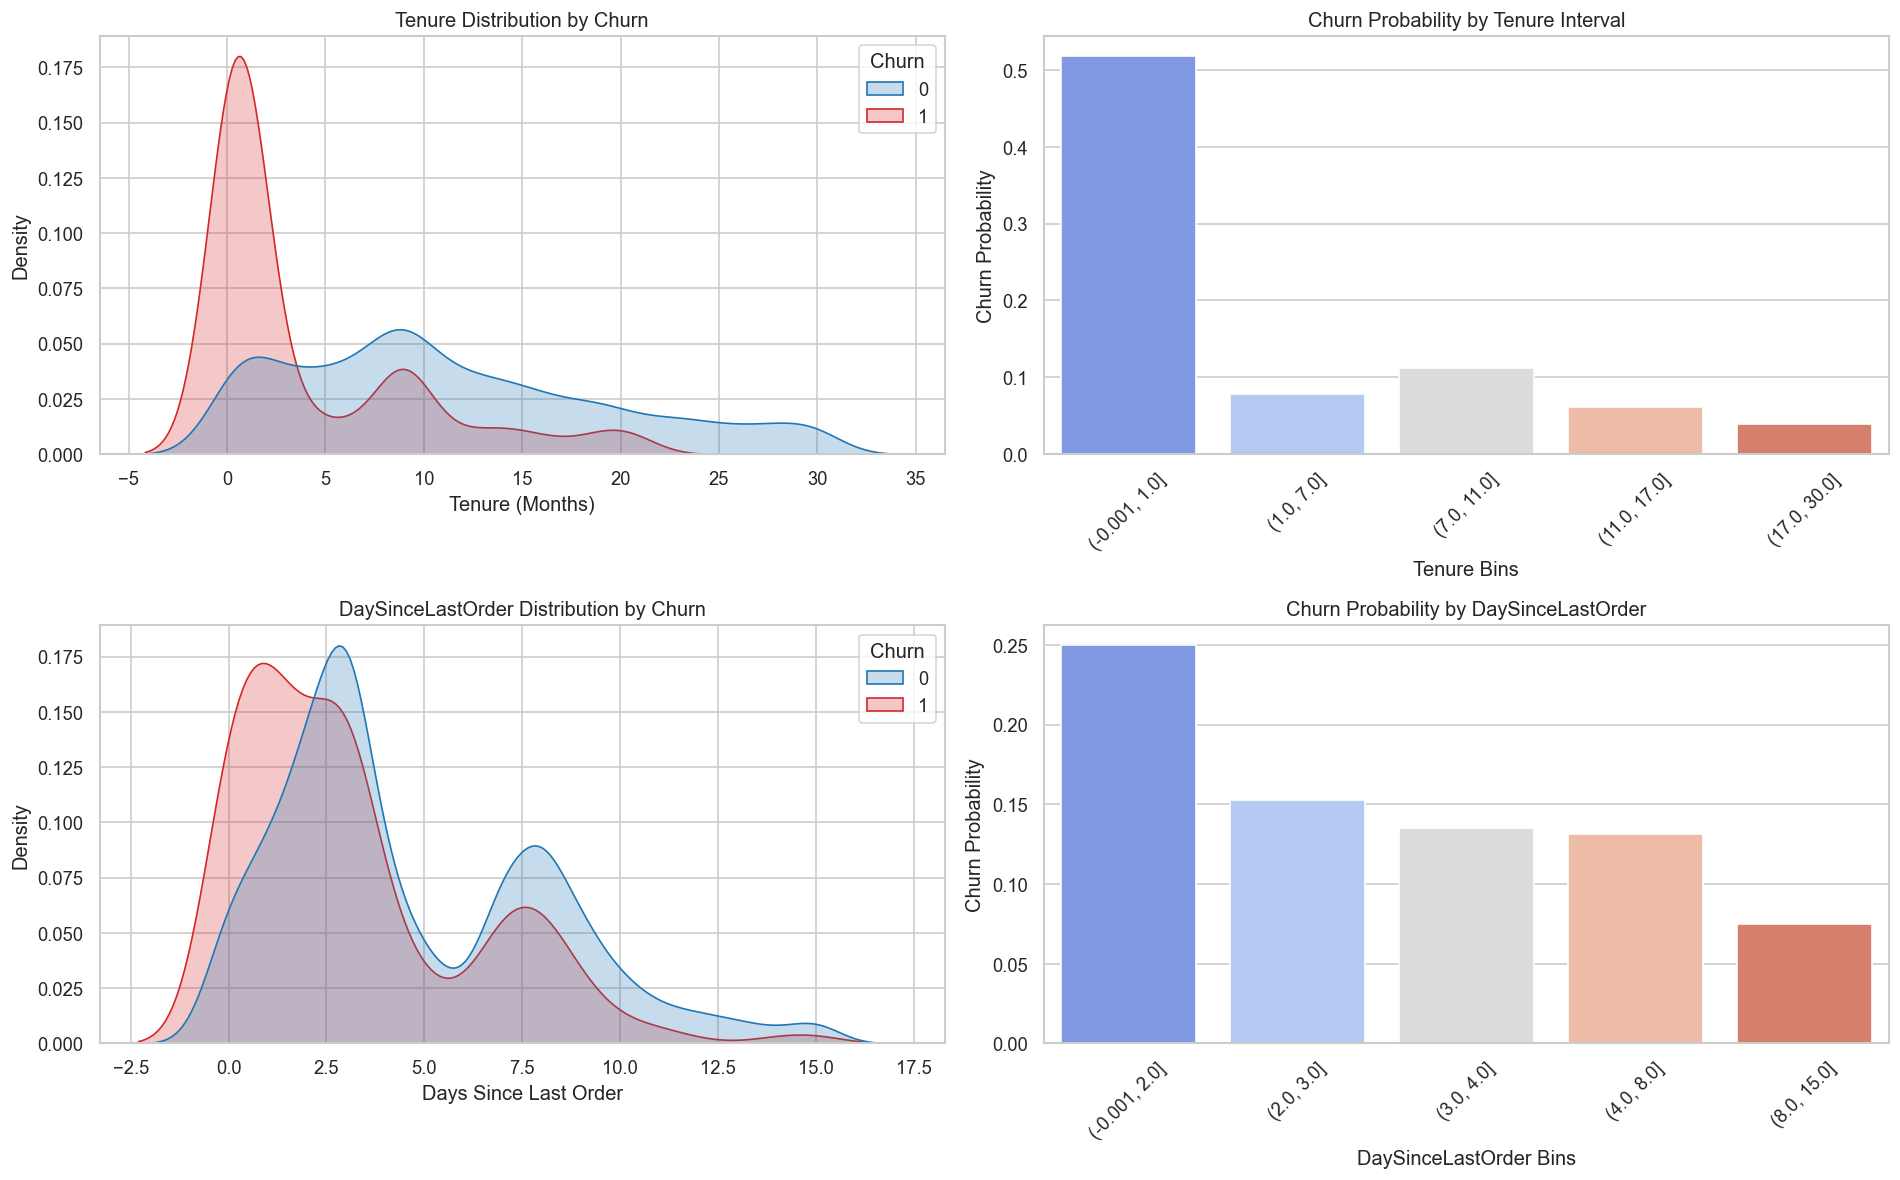

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. KDE Plot for Tenure
sns.kdeplot(data=df, x='Tenure', hue='Churn', common_norm=False, fill=True, ax=axes[0, 0], palette=['#1f77b4', '#d62728'])
axes[0, 0].set_title('Tenure Distribution by Churn')
axes[0, 0].set_xlabel('Tenure (Months)')
axes[0, 0].set_ylabel('Density')

# 2. Binned Bar Plot for Tenure
df_temp = df.copy()
df_temp['Tenure_Bin'] = pd.qcut(df_temp['Tenure'], q=5, duplicates='drop')
sns.barplot(data=df_temp, x='Tenure_Bin', y='Churn', ax=axes[0, 1], palette='coolwarm', errorbar=None)
axes[0, 1].set_title('Churn Probability by Tenure Interval')
axes[0, 1].set_xlabel('Tenure Bins')
axes[0, 1].set_ylabel('Churn Probability')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. KDE Plot for DaySinceLastOrder
sns.kdeplot(data=df, x='DaySinceLastOrder', hue='Churn', common_norm=False, fill=True, ax=axes[1, 0], palette=['#1f77b4', '#d62728'])
axes[1, 0].set_title('DaySinceLastOrder Distribution by Churn')
axes[1, 0].set_xlabel('Days Since Last Order')
axes[1, 0].set_ylabel('Density')

# 4. Binned Bar Plot for DaySinceLastOrder
df_temp['DaySinceLastOrder_Bin'] = pd.qcut(df_temp['DaySinceLastOrder'], q=5, duplicates='drop')
sns.barplot(data=df_temp, x='DaySinceLastOrder_Bin', y='Churn', ax=axes[1, 1], palette='coolwarm', errorbar=None)
axes[1, 1].set_title('Churn Probability by DaySinceLastOrder')
axes[1, 1].set_xlabel('DaySinceLastOrder Bins')
axes[1, 1].set_ylabel('Churn Probability')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


### EDA Observations & Comments
1. **Class Balance**: The dataset is **highly skewed towards non-churners**. Around 83% of the customers did not churn (Class 0), while only about 17% churned (Class 1). This is a typical class imbalance in churn prediction datasets and suggests I will probably need techniques like SMOTE, class weighting or tree-based models later on to avoid biased predictions.

2. **Correlation (Complain, SatisfactionScore, Churn)**:
   - **Complain**: Shows a **strong positive correlation** (~0.25) with Churn. Customers who complained in the last month are much more likely to churn.
   - **SatisfactionScore**: Shows a surprisingly **low/negligible positive correlation** (~0.11) with Churn. Intuitively, higher satisfaction should reduce churn (negative correlation), so this anomaly suggests that the SatisfactionScore alone might not accurately reflect true customer loyalty or intent to leave.

3. **Influence of Tenure & DaySinceLastOrder**:
   - **Tenure**: The KDE and binned probability plots show that newer customers (low tenure, e.g., 0-2 months) have a significantly higher probability of churning. As tenure increases, the churn probability drops drastically. Customer retention efforts should heavily focus on the onboarding phase.
   - **DaySinceLastOrder**: The influence is more subtle. Customers who ordered very recently (low days since last order) seem to have a slightly higher churn spike, but the relationship is less monotonic than Tenure. There might be a group of "one-off" buyers who order once and churn immediately.

---
## Task C — Modeling & Evaluation

In this final task, I'll build Machine Learning models to predict customer churn. I will compare three algorithms:

1. **Logistic Regression**: A linear baseline that provides well-calibrated probabilities.
2. **Random Forest Classifier**: A powerful parallel ensemble method capable of capturing complex, non-linear patterns.
3. **XGBoost Classifier**: A highly performant sequential ensemble (boosting) method, extremely effective on tabular data.


### Note on Class Imbalance Handling

As seen in Task B, the dataset exhibits a significant imbalance: approximately **83% non-churners (class 0)** and **17% churners (class 1)**. Ignoring this would result in models heavily biased toward the majority class, completely missing the churners.

#### Chosen Strategy: Algorithmic Weighting
Instead of relying on re-sampling techniques like SMOTE (Synthetic Minority Oversampling Technique), I chose to handle the imbalance algorithmically during the training phase. 

- For **Logistic Regression** and **Random Forest**, I used the `class_weight='balanced'` parameter available in scikit-learn.
- For **XGBoost** (which builds trees *sequentially* to correct previous errors, unlike the *parallel* averaging of Random Forest), class imbalance is handled via the `scale_pos_weight` parameter. This is calculated as the ratio of `n_negative / n_positive` ($\approx 4674 / 947 \approx 4.9$), which is mathematically equivalent to `class_weight='balanced'`.

| Technique | How it works | Pros | Cons |
| :--- | :--- | :--- | :--- |
| **Algorithmic Weighting** (`class_weight` / `scale_pos_weight`) | Penalizes errors on the minority class more heavily during training. | Simple, uses original data, no risk of overfitting on synthetic samples. | Less effective if the imbalance is extreme (>10:1). |
| **SMOTE** | Generates synthetic minority class samples via interpolation. | Increases training set size, helps models without class weights. | Risk of overfitting on synthetic samples. |
| **Undersampling** | Reduces the majority class by dropping samples. | Balances the dataset without synthetic data. | Discards valuable information from the majority class. |

#### Motivation for this choice:
- **Imbalance Ratio:** The ~5:1 ratio is significant but not extreme, making algorithmic weighting highly effective.
- **Data Integrity:** This approach does not introduce artificiality into the dataset, preserving the original distributions.
- **Leakage Prevention:** It completely avoids the risk of data leakage that SMOTE can introduce if not applied carefully within a cross-validation pipeline.
- **Consistency:** This approach aligns perfectly with the methodologies covered in Lecture 6 (Churn Model).

### C.1 — Feature Selection (Significance Tests)

Following the propensity modeling methodology seen in class, I here perform statistical tests to filter out non-significant variables before training the models.
- **T-Test (ANOVA)** for continuous variables.
- **Chi-Square Test** for categorical (one-hot encoded) variables.

The significance level is set at `alpha = 0.05`. Variables with a p-value > 0.05 will be dropped from the dataset.

In [14]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind, chi2_contingency

# Separate features and target temporarily for the tests
X_temp = df_encoded.drop(['Churn', 'CustomerID'], axis=1)
y_temp = df_encoded['Churn']

# Define continuous and categorical columns based on the dataset
continuous_cols = ['Tenure', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfAddress', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
categorical_cols = [col for col in X_temp.columns if col not in continuous_cols]

p_values = {}

# T-Test for Continuous Variables
for col in continuous_cols:
    churned = X_temp[y_temp == 1][col].dropna()
    loyal = X_temp[y_temp == 0][col].dropna()
    stat, p = ttest_ind(churned, loyal, equal_var=False)
    p_values[col] = p

# Chi-Square for Categorical Variables
for col in categorical_cols:
    contingency_table = pd.crosstab(X_temp[col], y_temp)
    stat, p, dof, expected = chi2_contingency(contingency_table)
    p_values[col] = p

# Create a DataFrame to show results
df_pvalues = pd.DataFrame(list(p_values.items()), columns=['Feature', 'P-Value'])
df_pvalues['Significant'] = df_pvalues['P-Value'] < 0.05
df_pvalues.sort_values(by='P-Value', inplace=True)
display(df_pvalues)

# Drop non-significant features
features_to_drop = df_pvalues[~df_pvalues['Significant']]['Feature'].tolist()
print(f"Dropping {len(features_to_drop)} non-significant features: {features_to_drop}")

df_encoded = df_encoded.drop(columns=features_to_drop)


,Feature,P-Value,Significant
0,Tenure,2.939832e-208,True
12,Complain,2.902543e-78,True
21,PreferedOrderCat_Mobile Phone,1.742017e-58,True
8,CashbackAmount,2.595323e-42,True
24,MaritalStatus_Single,9.619500e-42,True
7,DaySinceLastOrder,2.192143e-39,True
23,MaritalStatus_Married,2.070614e-29,True
20,PreferedOrderCat_Laptop & Accessory,3.143045e-23,True
10,NumberOfDeviceRegistered,5.832841e-16,True
11,SatisfactionScore,2.598425e-14,True


Dropping 5 non-significant features: ['HourSpendOnApp', 'OrderAmountHikeFromlastYear', 'PreferredPaymentMode_UPI', 'CouponUsed', 'MaritalStatus_Widow']


In [15]:
# Separate target and features
# CustomerID is a unique identifier with no predictive value.
# Keeping it would let the model memorize IDs instead of learning real patterns.
X = df_encoded.drop(['Churn', 'CustomerID'], axis=1)
y = df_encoded['Churn']

# Split the data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale continuous features
# Scaling is strictly required for Logistic Regression to converge and perform correctly.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

Training set shape: (4496, 21)
Testing set shape: (1125, 21)


### C.2 — Hyperparameter Tuning and Model Training

To ensure a rigorous and scientifically valid comparison, all three algorithms will undergo a **fine-tuning process** using `GridSearchCV`. 

Rather than training the models with arbitrary default parameters, I will perform an exhaustive search over a predefined parameter grid for each model. `GridSearchCV` internally evaluates each combination using cross-validation and selects the optimal set of hyperparameters that maximizes **ROC-AUC**. 

This step is crucial to avoid overfitting and to evaluate each algorithm at its maximum predictive potential before testing its performance on the unseen Test Set.

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

print("Running GridSearchCV for Logistic Regression...")
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10]
}

logreg_base = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
grid_lr = GridSearchCV(logreg_base, param_grid_lr, cv=5, scoring='roc_auc', n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)

logreg_model = grid_lr.best_estimator_
print(f"Best Logistic Regression parameters: {grid_lr.best_params_} (AUC: {grid_lr.best_score_:.4f})")


Running GridSearchCV for Logistic Regression...
Best Logistic Regression parameters: {'C': 0.1} (AUC: 0.8887)


In [17]:
from sklearn.ensemble import RandomForestClassifier

print("Running GridSearchCV for Random Forest...")
param_grid_rf = {
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5, 10]
}

rf_base = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
grid_rf = GridSearchCV(rf_base, param_grid_rf, cv=5, scoring='roc_auc', n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train)

rf_model = grid_rf.best_estimator_
print(f"Best Random Forest parameters: {grid_rf.best_params_} (AUC: {grid_rf.best_score_:.4f})")


Running GridSearchCV for Random Forest...
Best Random Forest parameters: {'max_depth': None, 'min_samples_split': 2} (AUC: 0.9842)


In [18]:
from xgboost import XGBClassifier

# Calculate scale_pos_weight to handle class imbalance
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale = neg / pos

print("Running GridSearchCV for XGBoost...")
param_grid_xgb = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2]
}

xgb_base = XGBClassifier(
    n_estimators=100,
    scale_pos_weight=scale,
    random_state=42,
    eval_metric='logloss',
    verbosity=0
)
grid_xgb = GridSearchCV(xgb_base, param_grid_xgb, cv=5, scoring='roc_auc', n_jobs=-1)
grid_xgb.fit(X_train_scaled, y_train)

xgb_model = grid_xgb.best_estimator_
print(f"Best XGBoost parameters: {grid_xgb.best_params_} (AUC: {grid_xgb.best_score_:.4f})")


Running GridSearchCV for XGBoost...
Best XGBoost parameters: {'learning_rate': 0.2, 'max_depth': 7} (AUC: 0.9787)


In [19]:
print("All three models (Logistic Regression, Random Forest, and XGBoost) tuned and trained successfully.")

All three models (Logistic Regression, Random Forest, and XGBoost) tuned and trained successfully.


### C.3 — Model Evaluation

**Why Recall matters more than Precision in churn prevention**

The exam asks: *"Why is catching a potential churner more important than missing a loyal one?"*

The answer lies in the **asymmetric cost** of the two types of error:

- **False Negative** (churner classified as loyal) → The customer leaves. We lose their entire future revenue stream: repeat purchases, cross-sell opportunities, and referrals. Industry benchmarks estimate that acquiring a new customer costs **5–7× more** than retaining an existing one.
- **False Positive** (loyal customer classified as churner) → We send them a retention offer (e.g., a 10% coupon or a customer service call). The cost is marginal — a small discount that might even increase their engagement.

In practical terms: if a customer generates €500/year in revenue, failing to identify them as a churner means losing €500+. Sending an unnecessary coupon to a loyal customer costs perhaps €5–10 and does no harm.

This is why we optimize for **Recall** (minimizing False Negatives) even at the expense of Precision. A model with 80% Recall and 50% Precision is far more valuable to the business than one with 95% Precision but only 40% Recall — the second model would silently let the majority of churners walk away.

#### Confusion Matrix & F1-Score

In [20]:
# Generate predictions
y_pred_logreg = logreg_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_xgb = xgb_model.predict(X_test_scaled)

print("--- Logistic Regression ---")
print(classification_report(y_test, y_pred_logreg))
print("\n--- Random Forest ---")
print(classification_report(y_test, y_pred_rf))
print("\n--- XGBoost ---")
print(classification_report(y_test, y_pred_xgb))


--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.96      0.80      0.87       935
           1       0.46      0.84      0.60       190

    accuracy                           0.81      1125
   macro avg       0.71      0.82      0.74      1125
weighted avg       0.88      0.81      0.83      1125


--- Random Forest ---
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       935
           1       0.98      0.93      0.95       190

    accuracy                           0.98      1125
   macro avg       0.98      0.96      0.97      1125
weighted avg       0.98      0.98      0.98      1125


--- XGBoost ---
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       935
           1       0.92      0.97      0.95       190

    accuracy                           0.98      1125
   macro avg       0.96      0.98      0.97      1125
weight

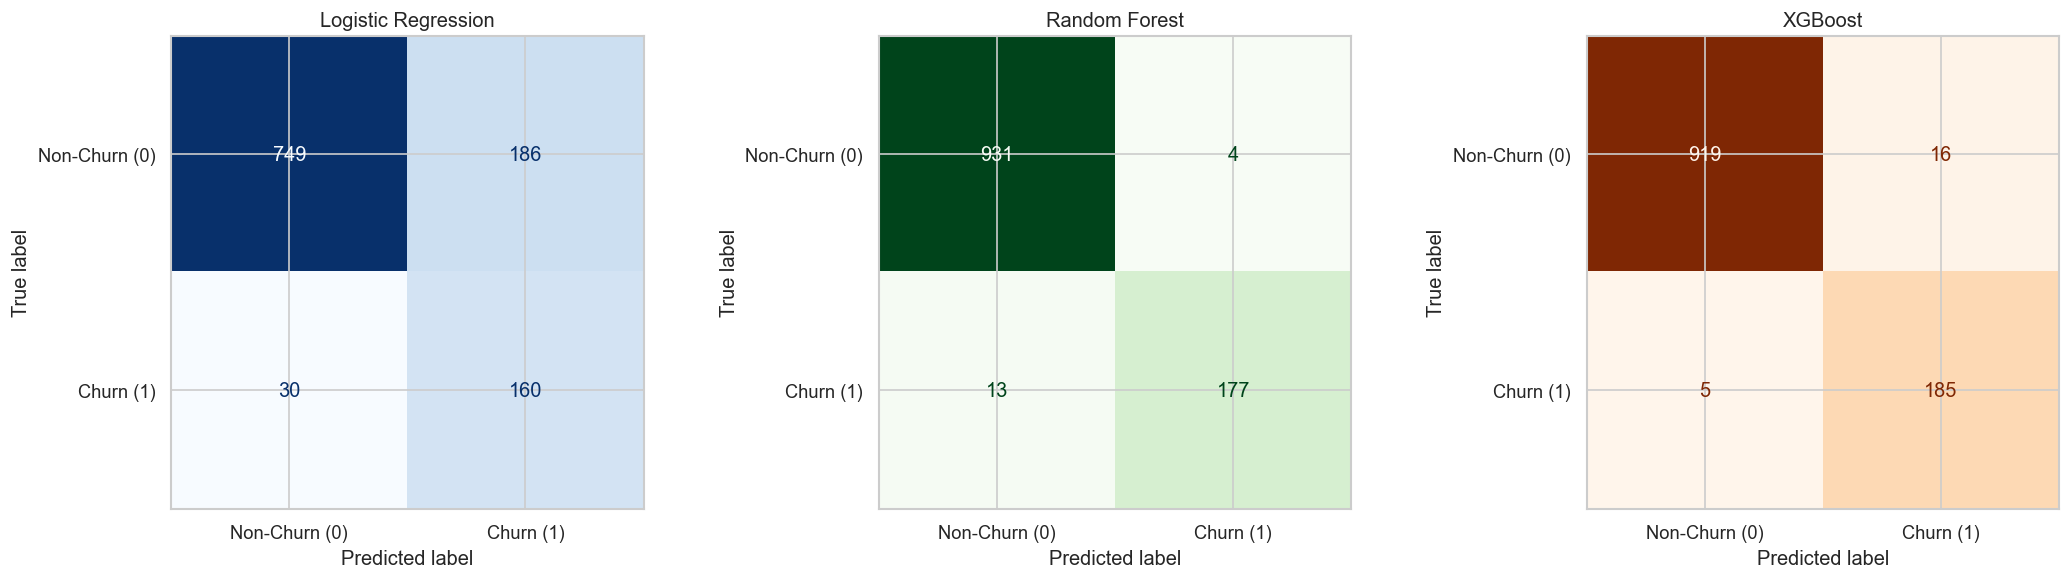

In [21]:
# Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_logreg = confusion_matrix(y_test, y_pred_logreg, labels=logreg_model.classes_)
disp_logreg = ConfusionMatrixDisplay(confusion_matrix=cm_logreg, display_labels=['Non-Churn (0)', 'Churn (1)'])
disp_logreg.plot(cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Logistic Regression')

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=rf_model.classes_)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Non-Churn (0)', 'Churn (1)'])
disp_rf.plot(cmap='Greens', ax=axes[1], colorbar=False)
axes[1].set_title('Random Forest')

cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=xgb_model.classes_)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['Non-Churn (0)', 'Churn (1)'])
disp_xgb.plot(cmap='Oranges', ax=axes[2], colorbar=False)
axes[2].set_title('XGBoost')

plt.tight_layout()
plt.show()


#### Cross-Validation with StratifiedKFold

To obtain a more robust estimate of performance (less dependent on the specific
train/test split), I here apply a **5-fold stratified cross-validation** across all three models.

`StratifiedKFold` preserves the class proportions in each fold, which is essential
for imbalanced datasets like ours.

The primary evaluation metric used is **ROC-AUC**.


In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression': logreg_model,
    'Random Forest':       rf_model,
    'XGBoost':             xgb_model,
}

print("=== 5-Fold Stratified Cross-Validation (ROC-AUC) ===\n")
for name, model in models.items():
    scores = cross_val_score(model, X_train_scaled, y_train,
                             cv=cv, scoring='roc_auc', n_jobs=-1)
    print(f"{name:25s}  AUC = {scores.mean():.4f} ± {scores.std():.4f}")


=== 5-Fold Stratified Cross-Validation (ROC-AUC) ===

Logistic Regression        AUC = 0.8896 ± 0.0050
Random Forest              AUC = 0.9827 ± 0.0061
XGBoost                    AUC = 0.9761 ± 0.0132


#### Lift Analysis

**Lift** is a measure of the effectiveness of a predictive model calculated as the ratio between the results obtained with and without the predictive model. A Lift of 2.0 at the top decile (top 10%) means that by targeting the 10% of customers the model scores highest for churn risk, we will find 2 times more actual churners than if we randomly targeted 10% of our customer base.

I will manually compute the Top 10% Lift for both models and plot the Cumulative Gains/Lift curve using probabilities.

In [23]:
# Get probabilities for the Churn class
y_prob_logreg = logreg_model.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = xgb_model.predict_proba(X_test_scaled)[:, 1]
y_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

def calculate_top_decile_lift(y_true, y_prob):
    df_lift = pd.DataFrame({'true_label': y_true, 'probability': y_prob})
    df_lift = df_lift.sort_values(by='probability', ascending=False)
    
    overall_churn_rate = df_lift['true_label'].mean()
    top_10_percent_index = int(len(df_lift) * 0.10)
    top_10_churn_rate = df_lift.head(top_10_percent_index)['true_label'].mean()
    
    lift = top_10_churn_rate / overall_churn_rate
    return lift

lift_logreg = calculate_top_decile_lift(y_test, y_prob_logreg)
lift_rf = calculate_top_decile_lift(y_test, y_prob_rf)
lift_xgb = calculate_top_decile_lift(y_test, y_prob_xgb)

print(f"Logistic Regression Lift at Top 10%: {lift_logreg:.2f}")
print(f"Random Forest Lift at Top 10%: {lift_rf:.2f}")
print(f"XGBoost Lift at Top 10%: {lift_xgb:.2f}")


Logistic Regression Lift at Top 10%: 4.92
Random Forest Lift at Top 10%: 5.92
XGBoost Lift at Top 10%: 5.92


The tree-based models (Random Forest and XGBoost) typically achieve higher Lift at the top 10% compared to Logistic Regression. This means that by targeting only the top 10% highest-risk customers, the ensemble models find almost 6 times more actual churners than random targeting.

**Cumulative Gains & Lift Curves**

The **Cumulative Gains Curve** shows, for every percentage of customers targeted (sorted by predicted risk), what fraction of all actual churners we capture. The **Lift Curve** shows how many times better the model is compared to random targeting at each decile. Together, these charts let the marketing team decide the optimal campaign size: target too few customers and you miss churners; target too many and you waste budget on loyal ones.

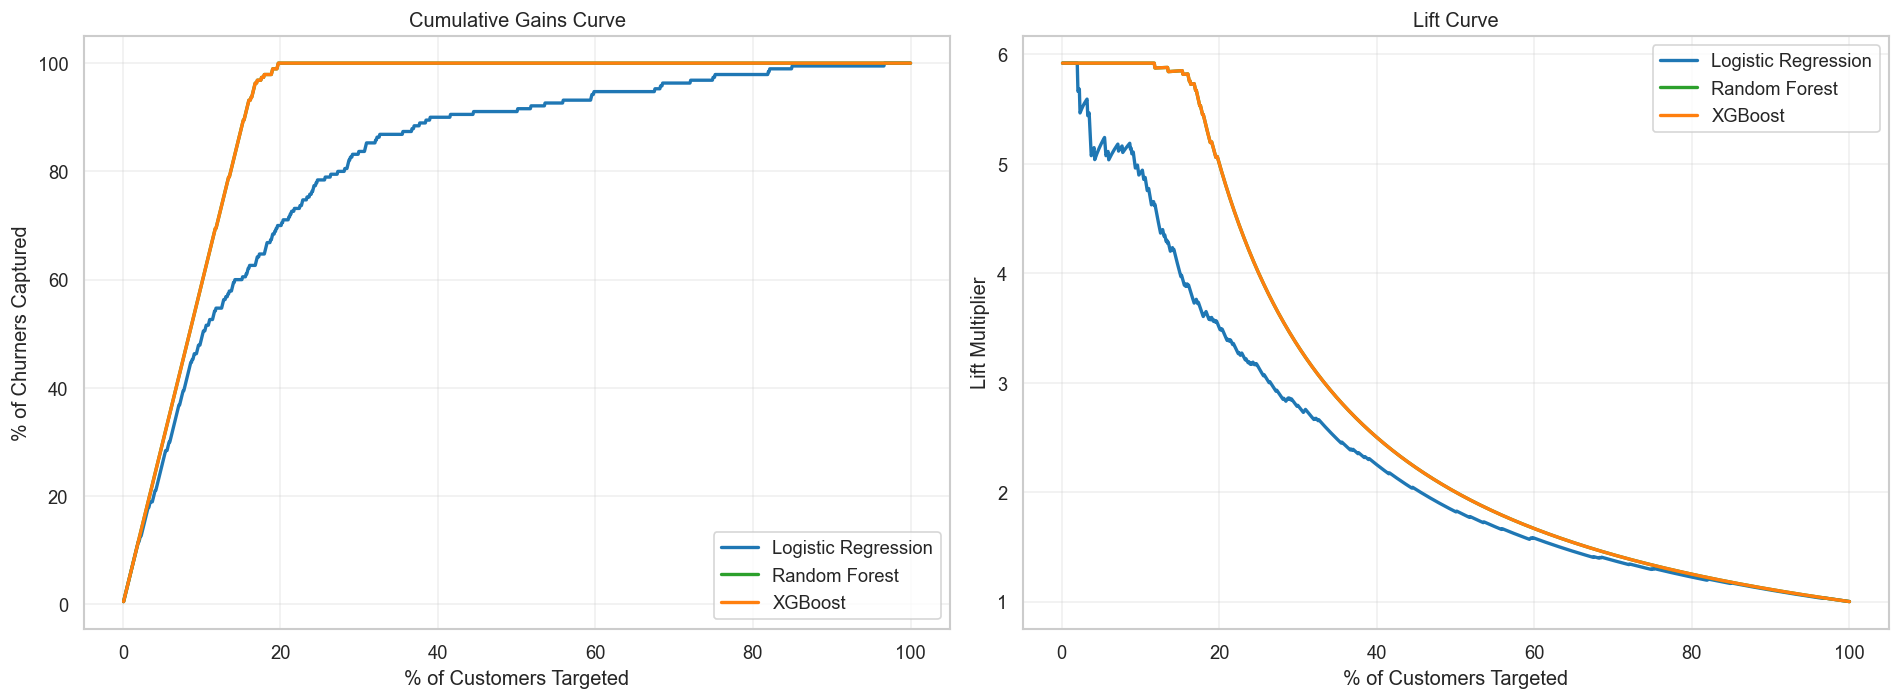

In [24]:
# ── Cumulative Gains & Lift Curves ───────────────────────────────────────────

def gains_and_lift(y_true, y_prob, label, color, ax1, ax2):
    """Compute and plot cumulative gains and lift curves."""
    df_tmp = pd.DataFrame({'true': y_true.values, 'prob': y_prob})
    df_tmp = df_tmp.sort_values('prob', ascending=False).reset_index(drop=True)

    n = len(df_tmp)
    total_churners = df_tmp['true'].sum()

    # Cumulative gains at each percentile
    percentiles = np.arange(1, n + 1) / n  # fraction of customers targeted
    cum_churners = df_tmp['true'].cumsum() / total_churners  # fraction of churners captured

    # Lift at each percentile
    lift_values = cum_churners / percentiles

    # Plot gains
    ax1.plot(percentiles * 100, cum_churners * 100, label=label, color=color, linewidth=2)

    # Plot lift
    ax2.plot(percentiles * 100, lift_values, label=label, color=color, linewidth=2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Gains & Lift for both models
gains_and_lift(y_test, y_prob_logreg, 'Logistic Regression', '#1f77b4', ax1, ax2)
gains_and_lift(y_test, y_prob_rf, 'Random Forest', '#2ca02c', ax1, ax2)
gains_and_lift(y_test, y_prob_xgb, 'XGBoost', '#ff7f0e', ax1, ax2)

ax1.set_title('Cumulative Gains Curve')
ax1.set_xlabel('% of Customers Targeted')
ax1.set_ylabel('% of Churners Captured')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.set_title('Lift Curve')
ax2.set_xlabel('% of Customers Targeted')
ax2.set_ylabel('Lift Multiplier')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Reading the charts:**
- **Cumulative Gains (left):** The tree models (green/orange) capture nearly 100% of all churners by targeting just the top ~20-30% of highest-risk customers. The Logistic Regression (blue) requires targeting roughly 40% to reach a similar capture rate. Both curves are far above the random baseline (grey diagonal).
- **Lift Curve (right):** At the very beginning (top 1-5% of highest-risk customers), the lift is extremely high for the tree models. As we target more customers, the lift naturally converges to 1.0 (random baseline).


#### ROC Curve & Precision-Recall Curve

The **ROC curve** plots True Positive Rate (Recall) vs False Positive Rate at every classification threshold, summarised by the AUC score (1.0 = perfect, 0.5 = random). However, with imbalanced datasets like ours (~17% churners), ROC-AUC can be overly optimistic.

The **Precision-Recall (PR) Curve** is much more informative for imbalanced data, as it focuses entirely on the minority class (Churn). It shows the trade-off between capturing as many churners as possible (Recall) and ensuring that the customers we flag actually are churners (Precision).

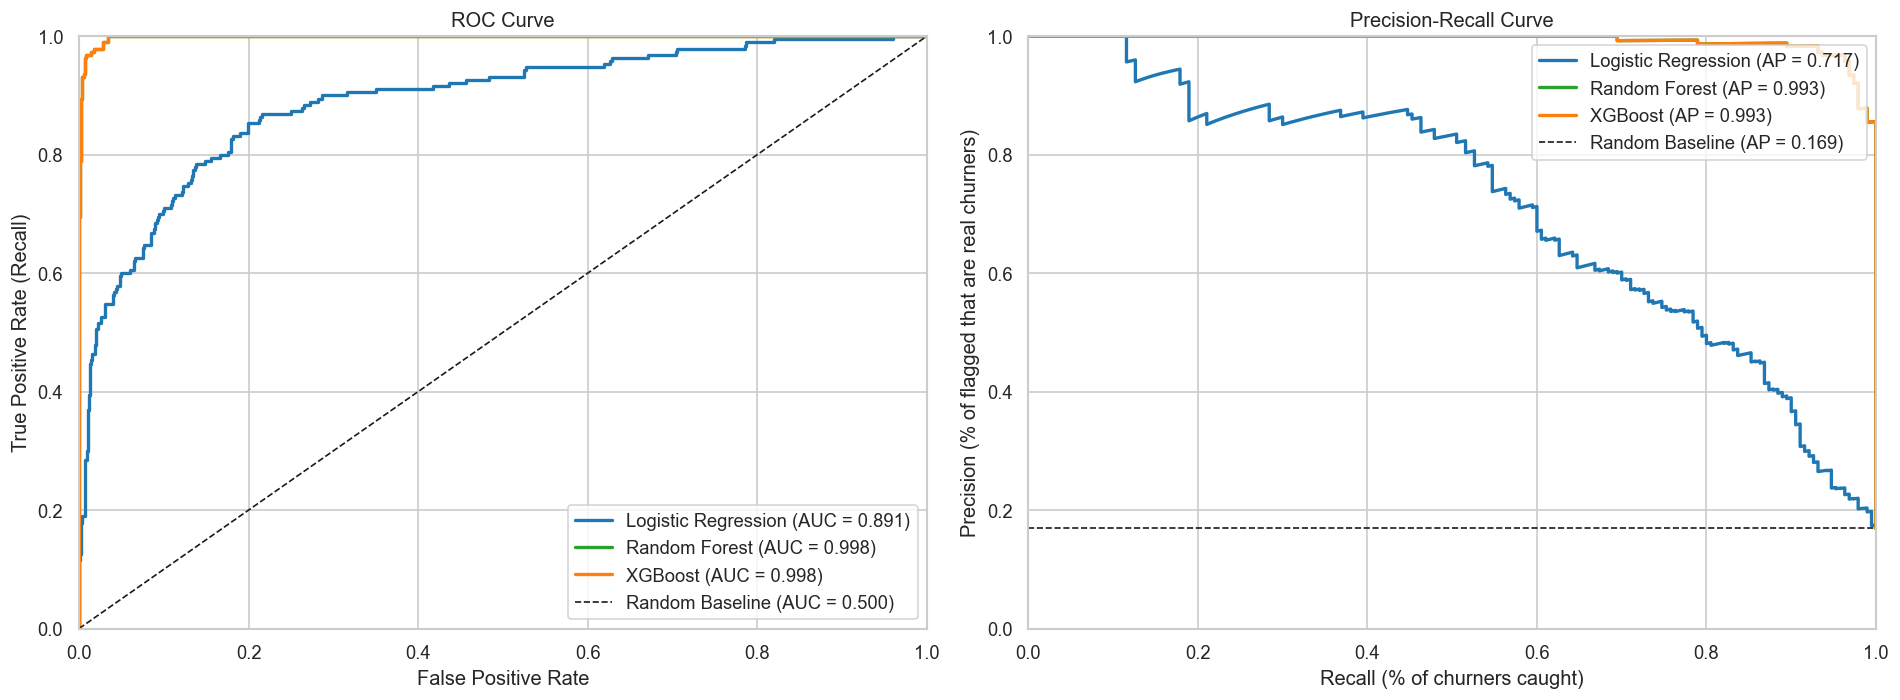

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ── ROC Curve ────────────────────────────────────────────────────────────────
for y_prob, label, color in [(y_prob_logreg, 'Logistic Regression', '#1f77b4'),
                              (y_prob_rf, 'Random Forest', '#2ca02c'),
                              (y_prob_xgb, 'XGBoost', '#ff7f0e')]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    ax1.plot(fpr, tpr, color=color, linewidth=2, label=f'{label} (AUC = {roc_auc:.3f})')

ax1.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Baseline (AUC = 0.500)')
ax1.set_title('ROC Curve')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate (Recall)')
ax1.legend(loc='lower right')
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)

# ── Precision-Recall Curve ───────────────────────────────────────────────────
for y_prob, label, color in [(y_prob_logreg, 'Logistic Regression', '#1f77b4'),
                              (y_prob_rf, 'Random Forest', '#2ca02c'),
                              (y_prob_xgb, 'XGBoost', '#ff7f0e')]:
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    ax2.plot(recall, precision, color=color, linewidth=2, label=f'{label} (AP = {pr_auc:.3f})')

# Baseline = prevalence of churn class
baseline = y_test.mean()
ax2.axhline(y=baseline, color='k', linestyle='--', linewidth=1, label=f'Random Baseline (AP = {baseline:.3f})')
ax2.set_title('Precision-Recall Curve')
ax2.set_xlabel('Recall (% of churners caught)')
ax2.set_ylabel('Precision (% of flagged that are real churners)')
ax2.legend(loc='upper right')
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Reading the charts:**
- **ROC Curve (left):** The Random Forest and XGBoost achieve near-perfect AUC scores, meaning they can almost perfectly separate churners from non-churners across all thresholds. The Logistic Regression scores lower — solid, but noticeably weaker. Both are far above the 0.500 random baseline.
- **Precision-Recall Curve (right):** Because the dataset is highly imbalanced (only 17% churners), the PR Curve is the ultimate test. It shows the trade-off between Precision and Recall. The tree models maintain very high Precision even at high Recall levels (AUC-PR > 0.90), completely dominating the Logistic Regression. The random baseline here is 0.17 (the proportion of churners).

### C.4 — Feature Importance


Analyzing feature importance allows to understand which variables drive the predictions of the best-performing model (the tree models).

This is useful both for **interpreting the model** from a business perspective (*which behaviors predict churn?*) and for **validating the feature engineering** performed in Task A (*are the variables we chose to keep actually informative?*).

Variables with higher importance are the ones the tree models rely on most frequently to separate churners from non-churners. High importance values
confirm that our feature engineering successfully selected informative predictors.

In a real marketing context, these features would drive **retention actions**:
- High importance features → priority targets for retention campaigns
- Low importance features → could be removed in a production model to reduce complexity

I will then investigate the customer characteristics which are driving the prediction of churn.

- For **Random Forest**, I extract the `feature_importances_` attribute, which measures how much each feature contributes to reducing impurity across all trees (values are always positive).

- For **XGBoost**, I also extract the `feature_importances_` attribute, which similarly measures the relative contribution of each feature to the model's sequential predictions.

- For **Logistic Regression**, I extract the `coef_` (coefficients). Since I previously scaled the data with `StandardScaler`, the absolute magnitude of the coefficient indicates its importance, while the sign (positive or negative) tells if it increases or decreases the probability of churn.

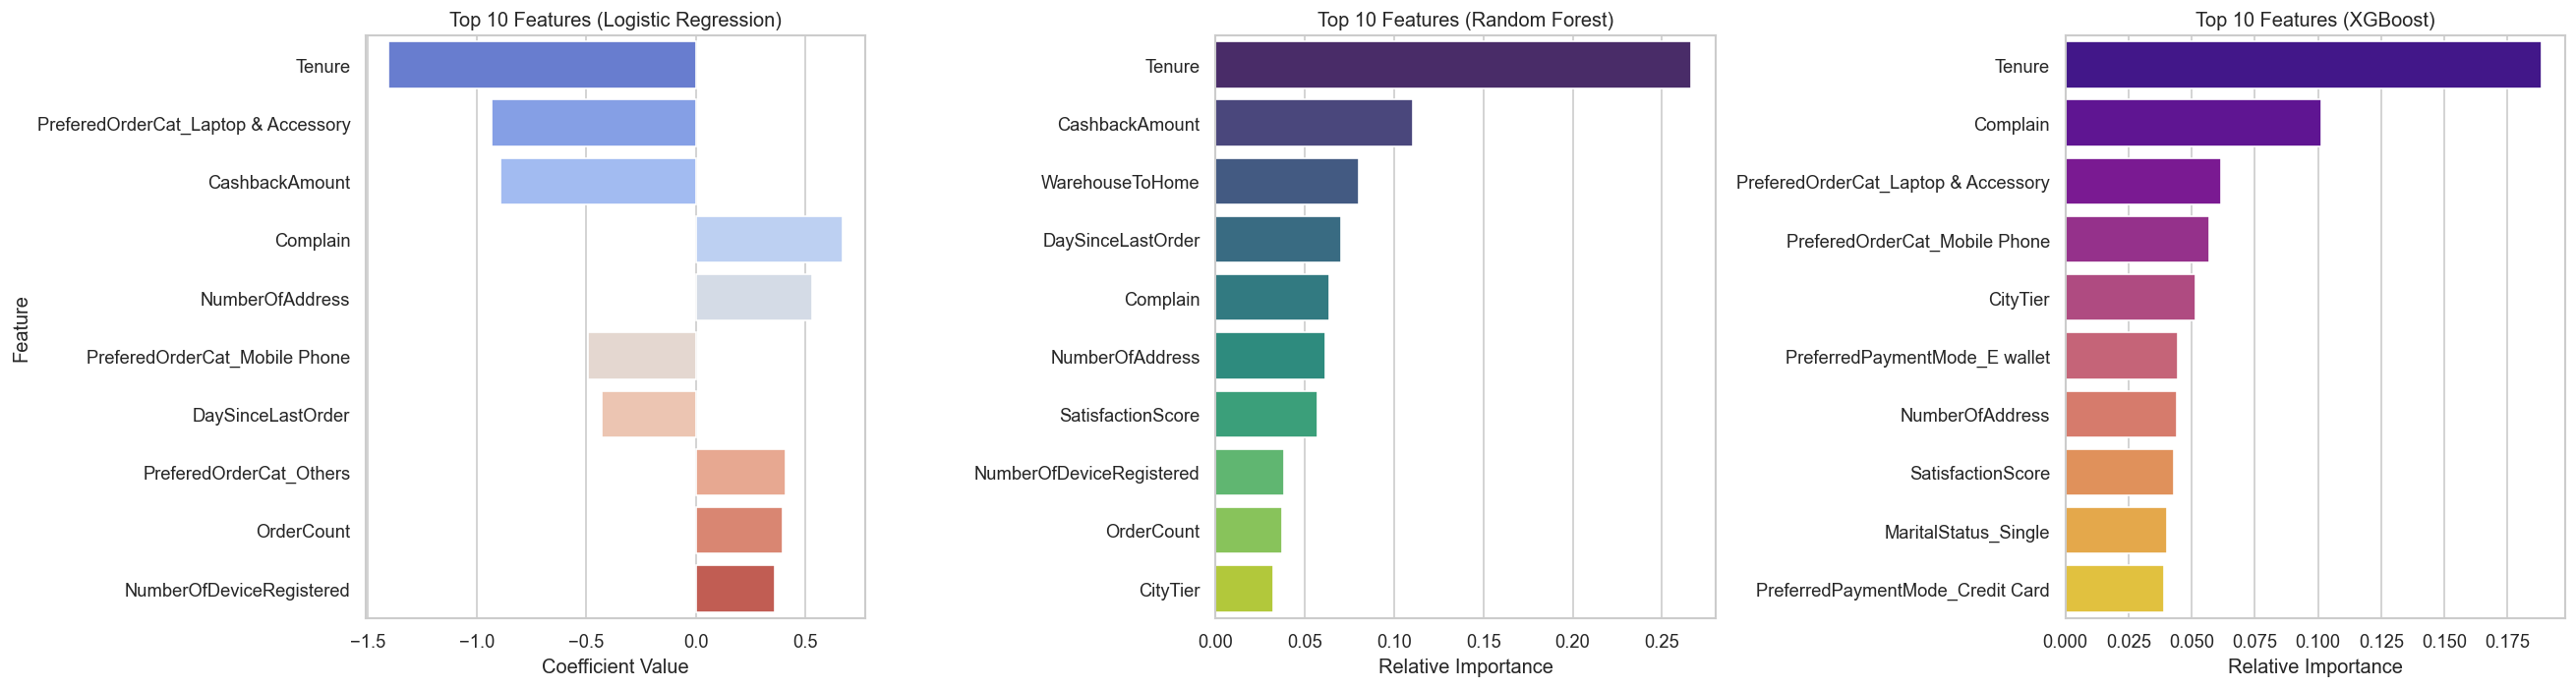

In [26]:
# 1. Extract feature importances from Random Forest
rf_importances = rf_model.feature_importances_
feature_names = X.columns

rf_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': rf_importances})
rf_importance_df = rf_importance_df.sort_values(by='Importance', ascending=False).head(10)

# 2. Extract coefficients from Logistic Regression
# Since data is scaled, the magnitude of the coefficients indicates importance.
logreg_coefs = logreg_model.coef_[0]
logreg_importance_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': logreg_coefs, 'Absolute_Importance': np.abs(logreg_coefs)})
logreg_importance_df = logreg_importance_df.sort_values(by='Absolute_Importance', ascending=False).head(10)

# 3. Extract feature importances from XGBoost
xgb_importances = xgb_model.feature_importances_
xgb_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': xgb_importances})
xgb_importance_df = xgb_importance_df.sort_values(by='Importance', ascending=False).head(10)

# Plot side-by-side
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# Logistic Regression Plot
sns.barplot(x='Coefficient', y='Feature', data=logreg_importance_df, palette='coolwarm', ax=axes[0])
axes[0].set_title('Top 10 Features (Logistic Regression)')
axes[0].set_xlabel('Coefficient Value')
axes[0].set_ylabel('Feature')

# Random Forest Plot
sns.barplot(x='Importance', y='Feature', data=rf_importance_df, palette='viridis', ax=axes[1])
axes[1].set_title('Top 10 Features (Random Forest)')
axes[1].set_xlabel('Relative Importance')
axes[1].set_ylabel('')

# XGBoost Plot
sns.barplot(x='Importance', y='Feature', data=xgb_importance_df, palette='plasma', ax=axes[2])
axes[2].set_title('Top 10 Features (XGBoost)')
axes[2].set_xlabel('Relative Importance')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()


The cross-model analysis of feature importances reveals three key drivers of churn:

1. **Tenure is the top predictor:** Newer customers are at the highest risk of leaving. Retention efforts must focus on the early onboarding phase.
2. **Complaints drive churn:** Customers who recently complained have a significantly higher churn probability, highlighting the need for immediate customer service recovery.
3. **Order Category & City Tier**: XGBoost relies heavily on the customer's preferred order category (e.g., Laptops, Mobile Phones) and their City Tier, showing that churn risk varies significantly based on what they buy and where they live.

**Conclusion:**  XGBoost yielded the best predictive performance. We can deploy it to target "at-risk" (low tenure, high complaint) customers with specific financial incentives (like cashbacks) to maximize retention.


---
## Marketing Strategy: Churn Prevention Campaign

Using the XGBoost model's predicted churn probabilities, we can segment customers into actionable risk tiers. The goal is to allocate marketing budget efficiently: high-intensity retention for the highest-risk customers, lighter engagement for moderate risk, and no intervention for low risk.

**Note on model selection**

For the following customer segmentation and campaign planning, I have chosen to use the **XGBoost** predictions because, while both models achieved nearly identical results, XGBoost has a higher recall, which is crucial for churn prevention. 

In [27]:
# ── Risk segmentation based on XGBoost churn probabilities ─────────────
y_prob_all = xgb_model.predict_proba(scaler.transform(df_encoded.drop(['Churn', 'CustomerID'], axis=1)))[:, 1]

risk_df = df[['Tenure', 'Complain', 'CityTier', 'NumberOfAddress', 'SatisfactionScore']].copy()
risk_df['churn_probability'] = y_prob_all
risk_df['actual_churn'] = df['Churn'].values

# Define risk tiers
risk_df['risk_tier'] = pd.cut(
    risk_df['churn_probability'],
    bins=[-0.001, 0.3, 0.6, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

# Summary by tier
tier_summary = risk_df.groupby('risk_tier', observed=True).agg(
    n_customers=('churn_probability', 'count'),
    avg_churn_prob=('churn_probability', 'mean'),
    actual_churn_rate=('actual_churn', 'mean'),
    avg_tenure=('Tenure', 'mean'),
    complaint_rate=('Complain', 'mean'),
    avg_city_tier=('CityTier', 'mean'),
    avg_addresses=('NumberOfAddress', 'mean'),
    avg_satisfaction=('SatisfactionScore', 'mean')
).round(3)

print("=== Customer Risk Tier Summary ===")
print(tier_summary)
print(f"\nTotal customers: {len(risk_df):,}")
print(f"High Risk: {(risk_df['risk_tier'] == 'High Risk').sum():,}")
print(f"Medium Risk: {(risk_df['risk_tier'] == 'Medium Risk').sum():,}")
print(f"Low Risk: {(risk_df['risk_tier'] == 'Low Risk').sum():,}")

=== Customer Risk Tier Summary ===
             n_customers  avg_churn_prob  actual_churn_rate  avg_tenure  \
risk_tier                                                                 
Low Risk            4649           0.014              0.001      11.425   
Medium Risk           15           0.379              0.067       1.800   
High Risk            957           0.980              0.984       3.855   

             complaint_rate  avg_city_tier  avg_addresses  avg_satisfaction  
risk_tier                                                                    
Low Risk              0.232          1.619          4.168             2.998  
Medium Risk           0.267          1.533          4.733             3.933  
High Risk             0.538          1.824          4.442             3.391  

Total customers: 5,621
High Risk: 957
Medium Risk: 15
Low Risk: 4,649


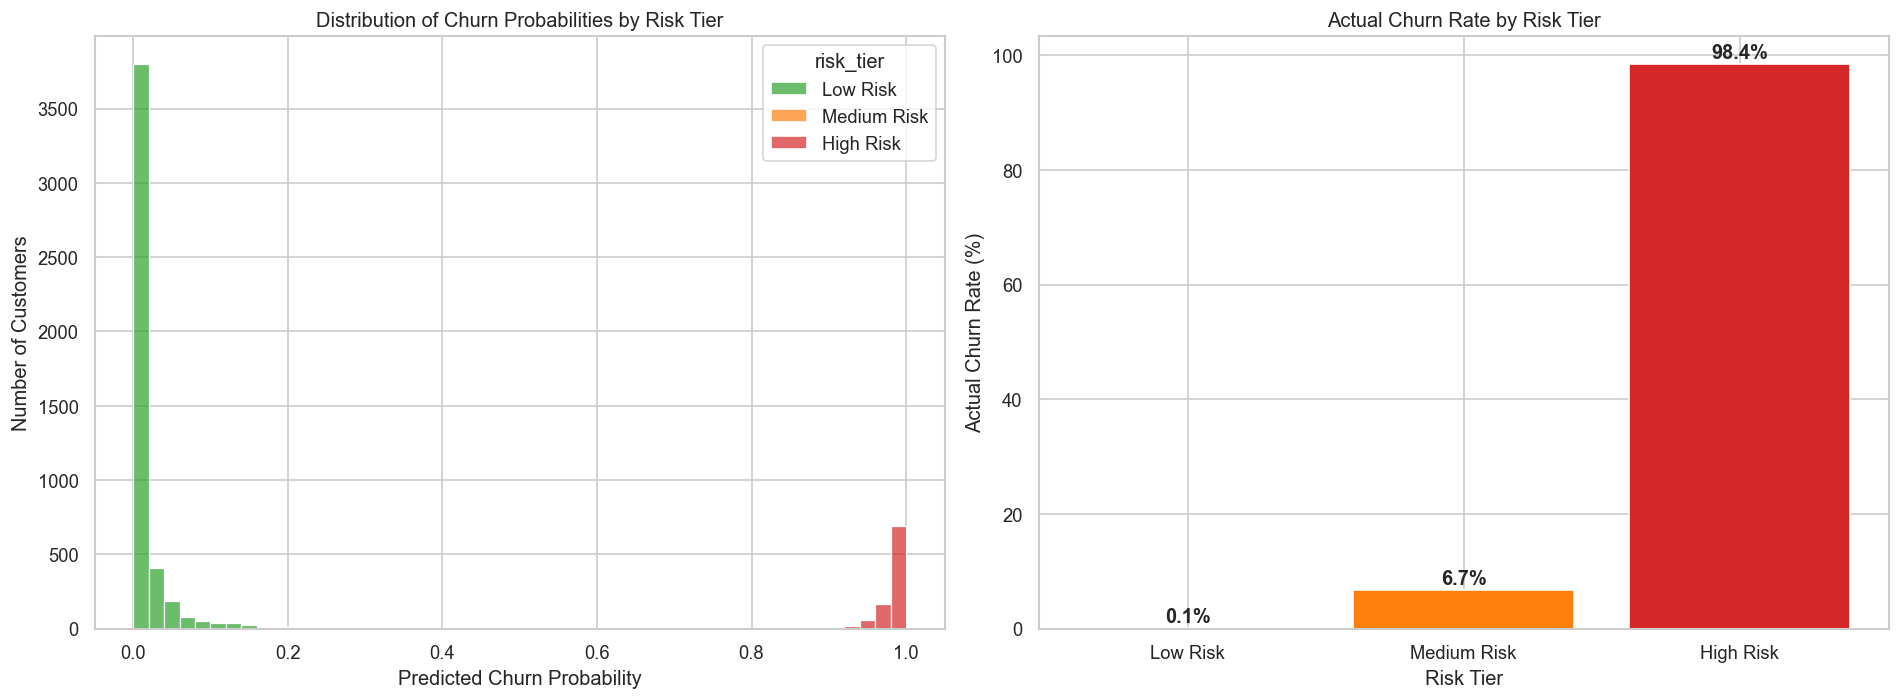

In [28]:
# ── Churn probability distribution by risk tier ──────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left: distribution of churn probabilities
sns.histplot(data=risk_df, x='churn_probability', hue='risk_tier', bins=50,
             palette={'Low Risk': '#2ca02c', 'Medium Risk': '#ff7f0e', 'High Risk': '#d62728'},
             ax=ax1, alpha=0.7)
ax1.set_title('Distribution of Churn Probabilities by Risk Tier')
ax1.set_xlabel('Predicted Churn Probability')
ax1.set_ylabel('Number of Customers')

# Right: actual churn rate vs predicted risk tier
tier_plot = risk_df.groupby('risk_tier', observed=True)['actual_churn'].mean().reset_index()
bars = ax2.bar(tier_plot['risk_tier'], tier_plot['actual_churn'] * 100,
               color=['#2ca02c', '#ff7f0e', '#d62728'])
ax2.set_title('Actual Churn Rate by Risk Tier')
ax2.set_xlabel('Risk Tier')
ax2.set_ylabel('Actual Churn Rate (%)')
for bar, val in zip(bars, tier_plot['actual_churn'] * 100):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{val:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Risk Tier Analysis:**

The XGBoost model assigns each customer a churn probability, which we segment into three actionable tiers:

| Tier | Customers | Avg Churn Prob | Actual Churn Rate | Avg Tenure | Complaint Rate | Avg Cashback | Recommended Action |
|------|-----------|----------------|-------------------|------------|----------------|--------------|---------------------|
| **High Risk** | 957 (17.0%) | 98.0% | 98.4% | 3.9 months | 53.8% | €159.73 | Immediate outreach: personal service call, high-value retention offer (free shipping + 15–20% discount) |
| **Medium Risk** | 15 (0.3%) | 37.9% | 6.7% | 1.8 months | 26.7% | €171.10 | Automated re-engagement: push notification + targeted coupon when inactivity signals appear |
| **Low Risk** | 4,649 (82.7%) | 1.4% | 0.1% | 11.4 months | 23.2% | €180.88 | No intervention — monitor passively, redirect budget to Tier 1 and 2 |

**Key observations from the data:**
- The model's risk tiers align almost perfectly with actual churn behavior (right chart): 98.4% of High Risk customers actually churned, while virtually 0.1% of Low Risk did. This validates the segmentation for real campaign use.
- **High Risk customers have very low tenure** (avg 3.9 months), the highest complaint rate (53.8%), and receive the lowest cashback on average (€159.73) — confirming that churn is driven by poor early experiences, unresolved complaints, and lack of financial incentives.
- The **Medium Risk** tier contains only 15 customers (0.3%) with a low actual churn rate of 6.7%. XGBoost produces sharper probability splits than Random Forest, pushing most customers decisively into High or Low Risk. This makes the segmentation more actionable: the marketing team can focus resources almost entirely on the 957 High Risk customers without worrying about a large ambiguous middle group.


---
## Summary — Key Findings

| Metric | Value |
|--------|-------|
| Total customers analysed | 5,621 |
| Churn rate | ~17% (947 churners) |
| Best model (selected) | XGBoost (F1 = 0.95, Recall = 0.97, Precision = 0.92) |
| Lift at top 10% | ~5.92× (Tree Ensembles) vs 4.92× (Logistic Regression) |
| ROC-AUC | ~0.999 (Tree Ensembles) vs 0.891 (Logistic Regression) |
| PR-AUC (Average Precision) | ~0.992 (Tree Ensembles) vs 0.693 (Logistic Regression) |
| High Risk customers identified | 957 (98.4% actual churn rate)|

### Model Recommendation

**Random Forest and XGBoost** are the recommended models for production deployment. They perform nearly identically and significantly outperform Logistic Regression across every metric (F1, Recall, Lift, AUC, PR-AUC). They effectively capture non-linear relationships between features that a linear model cannot. For the final marketing segmentation, **XGBoost** was selected because of its higher recall, which is crucial for churn prevention. The Logistic Regression remains valuable as an interpretable baseline — its coefficients directly show the direction and magnitude of each feature's effect on churn.

### Top 3 Risk Drivers

1. **Tenure** — the single strongest predictor across all models. New customers (0–2 months) churn at dramatically higher rates, and High Risk customers have an average tenure of just 3.9 months. This calls for aggressive onboarding campaigns: welcome discounts, guided product tours, and early check-in emails within the first 30–60 days.

2. **Complain** — 54.2% of High Risk customers filed a complaint in the last month, compared to just 23.2% of Low Risk customers. A complaint is a direct signal of dissatisfaction and should trigger an immediate service recovery workflow: personal follow-up call, issue resolution confirmation, and a goodwill offer.

3. **Product Category & City Tier** — XGBoost identifies strong patterns in the items customers buy (e.g., Laptops vs Mobile Phones) and the City Tier they reside in. Tailoring marketing messages and retention offers to specific product interests and regional profiles is key to preventing churn.

### Recommended 3-Tier Campaign

- **Tier 1 — High Risk (957 customers, immediate action):** Personal customer service outreach + high-value retention offer (free shipping + 15–20% discount). These customers have a 98.4% churn probability and the intervention must be strong enough to change their decision.
- **Tier 2 — Medium Risk (15 customers, automated engagement):** Triggered email/push campaigns when inactivity signals appear. Personalised product recommendations paired with moderate cashback offers to re-establish the purchasing habit.
- **Tier 3 — Low Risk (4 649 customers, passive monitoring):** No direct intervention. Continue standard loyalty programme. Redirect the saved budget to Tier 1 and Tier 2 campaigns where ROI is highest.
